In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

x=np.linspace(-5.0,5.0,100)
y=np.sqrt(10**2-x**2)
y=np.hstack([y,-y])
x=np.hstack([x,-x])

In [12]:
x1=np.linspace(-5.0,5.0,100)
y1=np.sqrt(5**2-x1**2)
y1=np.hstack([y1,-y1])
x1=np.hstack([x1,-x1])

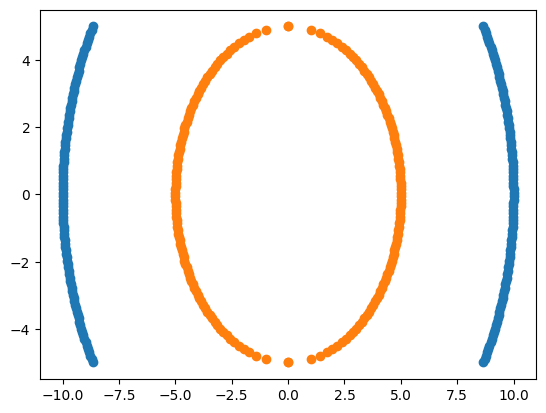

In [13]:
plt.scatter(y,x)
plt.scatter(y1,x1)

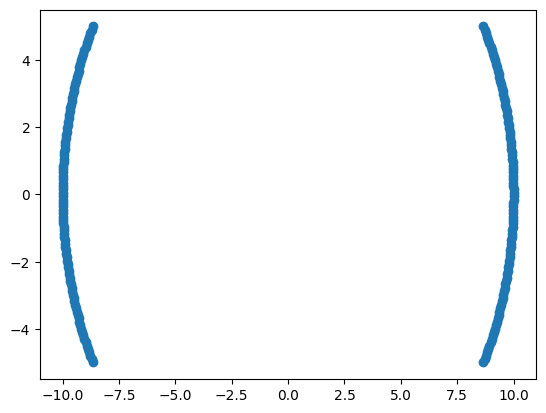

In [22]:
df1=pd.DataFrame(np.vstack([y,x]).T,columns=['X1','X2'])

In [29]:
df1["Y"] = 0
df2 = pd.DataFrame(np.vstack([y1, x1]).T, columns=['X1', 'X2'])
df2["Y"] = 1

df = pd.concat([df1, df2], ignore_index=True)
df.head(5)


,X1,X2,Y
0,8.660254,-5.00000,0
1,8.717792,-4.89899,0
2,8.773790,-4.79798,0
3,8.828277,-4.69697,0
4,8.881281,-4.59596,0


In [ ]:

x=df.iloc[:,:2]
y=df.Y



In [32]:
y

0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    1
399    1
Name: Y, Length: 400, dtype: int64

In [34]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=42)

In [35]:
from sklearn.svm import SVC
classmethods=SVC(kernel='linear')
classmethods.fit(x_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [36]:
from sklearn.metrics import accuracy_score
y_answer=classmethods.predict(x_test)
accuracy_score(y_test,y_answer)

0.48333333333333334

In [40]:
df['X1_square']=df["X1"]**2
df['X2_square']=df["X2"]**2
df['X1*X2']=(df['X1']*df['X2'])
df.head()



,X1,X2,Y,X1_square,X2_square,X1*X2
0,8.660254,-5.00000,0,75.000000,25.000000,-43.301270
1,8.717792,-4.89899,0,75.999898,24.000102,-42.708375
2,8.773790,-4.79798,0,76.979390,23.020610,-42.096467
3,8.828277,-4.69697,0,77.938476,22.061524,-41.466150
4,8.881281,-4.59596,0,78.877155,21.122845,-40.818009


In [41]:
x=df[['X1','X2','X1_square','X2_square','X1*X2']]

In [42]:
y=df['Y']

In [43]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=42)

In [45]:
x_train

,X1,X2,X1_square,X2_square,X1*X2
157,-9.971263,-0.757576,99.426079,0.573921,7.553987
109,-9.124936,4.090909,83.264463,16.735537,-37.329285
17,9.445795,-3.282828,89.223038,10.776962,-31.008922
347,-4.993619,0.252525,24.936231,0.063769,-1.261015
24,9.662581,-2.575758,93.365473,6.634527,-24.888466
...,...,...,...,...,...
71,9.761334,2.171717,95.283645,4.716355,21.198857
106,-8.982945,4.393939,80.693297,19.306703,-39.470515
270,4.551063,2.070707,20.712172,4.287828,9.423918
348,-4.997704,0.151515,24.977043,0.022957,-0.757228


In [54]:
import plotly.express as px

fig=px.scatter_3d(df,x="X1",y='X2',z='X1*X2',color='Y')
fig.show()

In [49]:
%pip install plotly.express

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.7 MB 10.1 MB/s eta 0:00:01
   --------------- ------------------------ 3.7/9.7 MB 9.7 MB/s eta 0:00:01
   ---------------------- ----------------- 5.5/9.7 MB 9.6 MB/s eta 0:00:01
   ---------------------------- ----------- 6.8/9.7 MB 8.4 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.7 MB 8.0 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.7 MB 6.4 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.7 MB 5.9 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.7 MB 5.2 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.7 MB 4.8 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.7 MB 4.7 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.7 MB 4.5 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 4.3 MB/s  0:00:02
   ------------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [56]:
fig=px.scatter_3d(df,x="X1_square",y='X2_square',z='X1*X2',color='Y')
fig.show()

In [61]:
classmethods=SVC(kernel="rbf")
classmethods.fit(x_train,y_train)
y_answer-classmethods.predict(x_test)
accuracy_score(y_test,y_answer)

0.48333333333333334